# Does the recommender go stale? Stage 2 and Champions 2026

The third test, and the first of a claim nothing has tested yet: the README says to retrain
**weekly**, because the meta shifts. Stage 2 and Champions 2026 (9 July to 18 October) came
after all the data the project was built on, with a new map (Summit), a changed pool and a
different meta. So the same model is scored three ways: retrained every week, every fourth
week, and never (trained once in July and left alone). **Committed to git before it ran.**

**Decided in advance:**

| | |
|---|---|
| Scored | Every line-up of Stage 2 and Champions 2026, read from vlr.gg by `fetch_vlr_matches.py` (checked first on 296 maps Kaggle also has: all matched) |
| History | All the Kaggle data from 2024, 2025 and 2026 (to Masters London, 21 June) |
| Methods | Notebook 14's five, settings unchanged, retrained every week as before |
| Added | Gradient boosting (the headline) retrained every fourth week with games, and never: fitted once, before the first week, on everything up to it |
| Measures, margin of error | As in notebooks 14 and 15: top-1, top-3, from scratch; 95% ranges from 5,000 resamples of whole matches, seed 0 |
| Verdict 1 | Weekly gradient boosting against the naive rule, by notebook 14's rule |
| Verdict 2 | Weekly against never retrained, on top-3. Range above zero: RETRAINING HELPS. Range includes zero: NO CLEAR GAIN FROM RETRAINING. Range below zero: RETRAINING HURTS |
| Breakdowns | Two only: by month (July to October), and Summit against the maps already known in July |

**Already seen before this ran:** how often each agent was played (Chamber in 52% of
Champions line-ups, Astra in 10.5%), which maps were played, and the app's suggestions for one
Summit line-up. No method has been scored on these games.

**Dry run, on development weeks only** (learning up to March 2025, scored on April to June
2025): weekly 91.9% top-3, every fourth week 89.0%, never retrained 86.9%, the naive rule
74.9%. Never retrained fell from level in the first week to 8 points behind after three months.

**Expected:** weekly a little below 2026's first half (87.4% top-3), still ahead of the naive
rule. Never retrained level with weekly in July, then falling further behind each month, more
than in the dry run because the meta moved more, and worst on Summit. Every fourth week in
between. How far "never" falls is the finding.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier

sys.path.insert(0, str(Path.cwd().parent / "src"))

pd.set_option("display.width", 200)

from dataset import build_map_table, load_vlr_maps
from recommend import Classifier, CoOccurrence, Popularity, lineup_table, summarise, walk_forward

SEED, RESAMPLES = 0, 5000
HEADLINE, BAR = "gradient boosting", "popularity (naive rule)"
EVERY_4, NEVER = "gradient boosting, retrained every 4th week", "gradient boosting, never retrained"
METHODS = {   # notebook 14's, unchanged
    "gradient boosting": lambda: Classifier(45, estimator=HistGradientBoostingClassifier(random_state=0)),
    "classifier + map x agent": lambda: Classifier(21, interactions=True),
    "co-occurrence": lambda: CoOccurrence(21),
    "classifier": lambda: Classifier(45),
    "popularity (naive rule)": lambda: Popularity(7),
}
RETRAIN = {HEADLINE: 1, EVERY_4: 4, NEVER: None}   # weeks with games between refits

INK, MUTED, RULE = "#2A3038", "#5A6570", "#D5DAE0"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": RULE, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": RULE, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
})

## The line-ups

In [2]:
kaggle = pd.concat([build_map_table(s) for s in ["vct_2024", "vct_2025", "vct_2026"]], ignore_index=True)
late = load_vlr_maps()
assert not set(late["game_id"]) & set(kaggle["game_id"]), "a scored map is also in the history"
assert late["played_at"].min() > kaggle["played_at"].max(), "the scored games must all come later"

history = lineup_table(kaggle)
to_score = lineup_table(late)      # line-ups only; results are not used

print(f"history : {len(history):,} line-ups, {history.played_at.min():%d %b %Y} to {history.played_at.max():%d %b %Y}")
print(f"scored  : {len(to_score):,} line-ups from {to_score.match_id.nunique()} matches, "
      f"{to_score.played_at.min():%d %b} to {to_score.played_at.max():%d %b %Y}, "
      f"over {to_score.played_at.dt.to_period('W').nunique()} weeks with games")
print(f"          x 5 hidden agents = {len(to_score) * 5:,} complete-a-line-up questions")

known_agents = {a for lineup in history["agents"] for a in lineup}
new_agents = sorted({a for lineup in to_score["agents"] for a in lineup} - known_agents)
new_maps = sorted(set(to_score["map"]) - set(history["map"]))
print(f"\nagents never played before: {new_agents or 'none'}")
print(f"maps never played before: {new_maps or 'none'}")

history : 6,524 line-ups, 17 Feb 2024 to 21 Jun 2026
scored  : 1,404 line-ups from 280 matches, 09 Jul to 18 Oct 2026, over 13 weeks with games
          x 5 hidden agents = 7,020 complete-a-line-up questions

agents never played before: none
maps never played before: ['Summit']


## Run every method once

Gradient boosting refits every week, so this takes several minutes.

In [3]:
runs = {name: walk_forward(history, to_score, make) for name, make in METHODS.items()}
for name, every in RETRAIN.items():
    if every != 1:
        runs[name] = walk_forward(history, to_score, METHODS[HEADLINE], retrain_every=every)

## The result

In [4]:
results = pd.DataFrame({name: summarise(r) for name, r in runs.items()}).T
print(f"{len(to_score):,} line-ups from Stage 2 and Champions 2026.  "
      f"Picking at random from the ~23 agents left gets top-3 about 13%.\n")
print(results.to_string(formatters={"top-1": "{:.1%}".format, "top-3": "{:.1%}".format,
                                    "from scratch, of 5": "{:.2f}".format}))

1,404 line-ups from Stage 2 and Champions 2026.  Picking at random from the ~23 agents left gets top-3 about 13%.

                                            top-1 top-3 from scratch, of 5
gradient boosting                           67.0% 89.4%               3.23
classifier + map x agent                    69.8% 90.5%               3.25
co-occurrence                               70.5% 88.7%               3.22
classifier                                  67.5% 89.2%               3.31
popularity (naive rule)                     51.2% 73.7%               3.35
gradient boosting, retrained every 4th week 63.3% 86.6%               3.23
gradient boosting, never retrained          57.2% 81.4%               3.11


## The margin of error, and the two verdicts

In [5]:
def per_lineup(result, cutoff):
    return (np.vstack(result["ranks"].to_numpy()) <= cutoff).mean(axis=1)

for run in runs.values():   # every method answered the same line-ups, in the same order
    assert run.index.equals(runs[HEADLINE].index)

match_of = runs[HEADLINE]["match_id"].to_numpy()
match_ids = np.unique(match_of)
rows_of = {m: np.flatnonzero(match_of == m) for m in match_ids}
rng = np.random.default_rng(SEED)
draws = [np.concatenate([rows_of[m] for m in rng.choice(match_ids, len(match_ids))]) for _ in range(RESAMPLES)]

def interval(values):
    return np.percentile([values[d].mean() for d in draws], [2.5, 97.5])

for name in [HEADLINE, EVERY_4, NEVER]:
    for label, cutoff in [("top-3", 3), ("top-1", 1)]:
        v = per_lineup(runs[name], cutoff)
        lo, hi = interval(v)
        print(f"{name:44} {label}: {v.mean():.1%}   95% range {lo:.1%} to {hi:.1%}")

def lead(a, b):
    diff = per_lineup(runs[a], 3) - per_lineup(runs[b], 3)
    lo, hi = interval(diff)
    print(f"   top-3, {a} minus {b}: {diff.mean() * 100:+.1f} points   95% range {lo * 100:+.1f} to {hi * 100:+.1f}")
    return diff.mean(), lo, hi

print("\nVERDICT 1: the weekly model against the naive rule")
mean, lo, hi = lead(HEADLINE, BAR)
if mean > 0 and lo > 0:
    verdict_1 = "BEATS THE NAIVE RULE"
elif mean > 0:
    verdict_1 = "AHEAD, BUT NOT DISTINGUISHABLE FROM THE NAIVE RULE"
else:
    verdict_1 = "DOES NOT BEAT THE NAIVE RULE"
print(f"   by the rule decided in advance: {verdict_1}")

print("\nVERDICT 2: retrained every week against never retrained")
mean, lo, hi = lead(HEADLINE, NEVER)
verdict_2 = ("RETRAINING HELPS" if lo > 0 else "RETRAINING HURTS" if hi < 0
             else "NO CLEAR GAIN FROM RETRAINING")
print(f"   by the rule decided in advance: {verdict_2}")

print("\nNot verdicts, for reading them:")
_ = lead(HEADLINE, EVERY_4)
_ = lead(NEVER, BAR)

gradient boosting                            top-3: 89.4%   95% range 88.3% to 90.5%
gradient boosting                            top-1: 67.0%   95% range 65.3% to 68.6%
gradient boosting, retrained every 4th week  top-3: 86.6%   95% range 85.3% to 87.8%
gradient boosting, retrained every 4th week  top-1: 63.3%   95% range 61.5% to 65.1%
gradient boosting, never retrained           top-3: 81.4%   95% range 80.1% to 82.7%
gradient boosting, never retrained           top-1: 57.2%   95% range 55.6% to 58.9%

VERDICT 1: the weekly model against the naive rule
   top-3, gradient boosting minus popularity (naive rule): +15.7 points   95% range +14.4 to +17.0
   by the rule decided in advance: BEATS THE NAIVE RULE

VERDICT 2: retrained every week against never retrained
   top-3, gradient boosting minus gradient boosting, never retrained: +8.0 points   95% range +6.9 to +9.2
   by the rule decided in advance: RETRAINING HELPS

Not verdicts, for reading them:


   top-3, gradient boosting minus gradient boosting, retrained every 4th week: +2.8 points   95% range +2.0 to +3.6
   top-3, gradient boosting, never retrained minus popularity (naive rule): +7.7 points   95% range +6.3 to +9.1


## The two pre-registered breakdowns

### 1. Month by month: how fast does it go stale?

top-3 by month

         line-ups gradient boosting gradient boosting, retrained every 4th week gradient boosting, never retrained popularity (naive rule) weekly minus never, points
month                                                                                                                                                                
2026-07       466             86.5%                                       82.4%                              82.4%                   70.8%                       +4.1
2026-08       710             90.2%                                       88.3%                              82.4%                   75.0%                       +7.8
2026-09       112             90.9%                                       90.0%                              77.1%                   70.9%                      +13.7
2026-10       116             94.7%                                       89.7%                              75.2%                   80.3%                

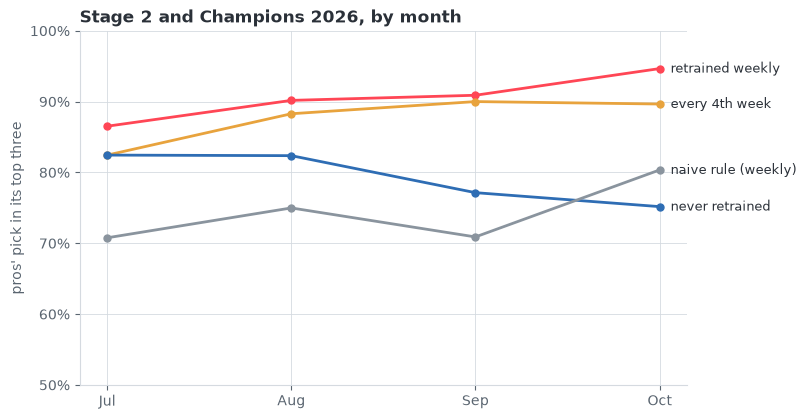

In [6]:
SHOWN = [HEADLINE, EVERY_4, NEVER, BAR]
month = to_score.loc[runs[HEADLINE].index, "played_at"].dt.to_period("M").rename("month")
top3 = pd.DataFrame({name: per_lineup(runs[name], 3) for name in SHOWN}, index=runs[HEADLINE].index)
by_month = top3.groupby(month).mean()
by_month.insert(0, "line-ups", month.value_counts().sort_index())
by_month["weekly minus never, points"] = (by_month[HEADLINE] - by_month[NEVER]) * 100
print("top-3 by month\n")
print(by_month.to_string(formatters={**{n: "{:.1%}".format for n in SHOWN},
                                     "weekly minus never, points": "{:+.1f}".format}))

colours = {HEADLINE: "#FF4655", EVERY_4: "#E8A33D", NEVER: "#2E6DB4", BAR: "#8A949E"}
labels = {HEADLINE: "retrained weekly", EVERY_4: "every 4th week", NEVER: "never retrained",
          BAR: "naive rule (weekly)"}
fig, ax = plt.subplots(figsize=(9, 4.6))
x = [p.strftime("%b") for p in by_month.index]
ends = []
for name in SHOWN:
    ax.plot(x, by_month[name], color=colours[name], lw=2, marker="o", ms=5)
    ends.append([by_month[name].iloc[-1], labels[name]])
ends.sort(reverse=True)                      # top to bottom, then push apart any that crowd
for i in range(1, len(ends)):
    ends[i][0] = min(ends[i][0], ends[i - 1][0] - 0.03)
for y, label in ends:
    ax.annotate(label, (len(x) - 1, y), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=9, color=INK)
ax.set_ylim(0.5, 1)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_ylabel("pros' pick in its top three")
ax.set_title("Stage 2 and Champions 2026, by month", loc="left")
fig.subplots_adjust(right=0.8)
plt.show()

### 2. Summit, a map no model had seen in July

In [7]:
on_new = runs[HEADLINE]["map"].isin(new_maps)
groups = [(f"{', '.join(new_maps)} (new)", on_new), ("maps known in July", ~on_new)] if new_maps \
    else [("every map was known in July", ~on_new)]
for label, mask in groups:
    print(f"{label}: {mask.sum():,} line-ups")
    for name in SHOWN:
        part = runs[name][mask]
        print(f"   {name:44} " + "   ".join(
            f"{k} {v:.1%}" if k != "from scratch, of 5" else f"{k} {v:.2f}" for k, v in summarise(part).items()))
    print()

Summit (new): 190 line-ups
   gradient boosting                            top-1 53.6%   top-3 81.1%   from scratch, of 5 2.57
   gradient boosting, retrained every 4th week  top-1 44.7%   top-3 73.8%   from scratch, of 5 2.51
   gradient boosting, never retrained           top-1 30.0%   top-3 56.7%   from scratch, of 5 2.41
   popularity (naive rule)                      top-1 31.4%   top-3 56.0%   from scratch, of 5 2.71

maps known in July: 1,214 line-ups
   gradient boosting                            top-1 69.0%   top-3 90.7%   from scratch, of 5 3.33
   gradient boosting, retrained every 4th week  top-1 66.2%   top-3 88.6%   from scratch, of 5 3.34
   gradient boosting, never retrained           top-1 61.5%   top-3 85.2%   from scratch, of 5 3.23
   popularity (naive rule)                      top-1 54.3%   top-3 76.5%   from scratch, of 5 3.45

